---
title: "Target the Right Customers with Thinking Mode"
description: "Rank 200,000 bank customers by how likely they are to transact, and see what each Thinking effort level adds to the top of the list."
cookbookTags:
  - thinking mode
  - api
  - classification
authors:
  - name: Prior Labs
    linkedin: https://www.linkedin.com/company/prior-labs
    twitter: https://twitter.com/prior_labs
featured: true
---
A bank has 200,000 customers and wants to know which of them will make a particular
kind of transaction in the coming period. Only one in ten will. The point of the
model is not to label every customer correctly; it is to put the right customers at
the top of a list, because the list is what the business acts on. A campaign
reaches the first 10% or 20% of it, and everyone further down is never contacted.

This is the shape of most customer-targeting problems: which leads to call, which
accounts to prioritize, which users to offer an upgrade. The data is wide and
anonymized, the signal is thin, and the question is how much better a ranking can
get without new data.

This notebook fits the base TabPFN 3.5 model on the
[Santander Customer Transaction Prediction](https://www.kaggle.com/c/santander-customer-transaction-prediction)
dataset, then turns on Thinking mode at two effort levels and measures what changes,
both in the usual metrics and in how many transactors end up in the top of the list.

## Setup

Install the client and dependencies (Thinking effort levels require `tabpfn-client` 0.7.1+).
In Colab, add `TABPFN_TOKEN` to Secrets; elsewhere, use your usual client authentication.

In [ ]:
%pip install -q --upgrade tabpfn-client==0.7.1 pandas==2.3.3 numpy==2.5.3 scikit-learn==1.9.0 matplotlib==3.11.2 pyarrow==25.0.1 huggingface-hub==1.31.0

In [1]:
import os

try:
    from google.colab import userdata
except ImportError:
    pass
else:
    os.environ["TABPFN_TOKEN"] = userdata.get("TABPFN_TOKEN")

In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download
from IPython.display import display
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from tabpfn_client import TabPFNClassifier

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})

## The data

We use the [BeyondArena](https://huggingface.co/datasets/TabArena/BeyondArena) copy
of the Kaggle training set: 200,000 customers, a binary target, and 200 anonymized
numeric features. BeyondArena adds two indicator columns per feature that encode
whether a value is unique in the dataset, a pattern the competition's top entries
relied on, which brings the width to 600 columns. The features have no names and
no documented meaning, so there is nothing to engineer by hand. That is the
situation this notebook is about: the model has to find what it can in the
columns as given.

BeyondArena publishes fixed splits. We take the first fold of the first repetition:
133,333 customers to train on and 66,667 held out. Credit: Santander Bank via
Kaggle, used under the competition rules.

In [3]:
def download_file(filename):
    return hf_hub_download(
        "TabArena/BeyondArena",
        f"santander_customer_transaction_prediction/019d7373-33b4-7002-948b-c14d1fffe341/{filename}",
        repo_type="dataset", revision="88059a3f02ec4abb6ec24bbe0d1c0b7eed31485d",
    )

customers = pd.read_parquet(download_file("dataset.parquet"))
published_splits = json.loads(Path(download_file(
    "experiment_metadata.predictive-ml-splits-mold-v1.json"
)).read_text())["splits"]
train_idx, test_idx = published_splits["0"]["0"]

X_train = customers.iloc[train_idx].drop(columns="target")
y_train = customers.iloc[train_idx]["target"].to_numpy()
X_test = customers.iloc[test_idx].drop(columns="target")
y_test = customers.iloc[test_idx]["target"].to_numpy()
print(f"{len(X_train):,} training customers; {len(X_test):,} held-out customers; "
      f"{X_train.shape[1]} features; {y_train.mean():.1%} transact")

133,333 training customers; 66,667 held-out customers; 600 features; 10.0% transact


## What to measure

Three metrics, each answering a different question:

- **ROC AUC** is the dataset's own objective and the one Thinking optimizes here. It
  measures ranking quality across the whole list.
- **Average precision** measures ranking quality where it matters for targeting, at
  the top of the list. With 10% positives, ROC AUC can look healthy while the top
  decile is mediocre; average precision will not.
- **Log-loss** measures whether the probabilities are calibrated, which matters if
  the scores feed a budget or an expected-value calculation rather than a cutoff.

We also report one number a campaign manager would ask for: of all customers who
transact, what share are in the top 10% of the ranked list? A random list captures
10%. The helper below fits a model, times it, and returns all four.

In [4]:
def captured_in_top(probability, y_true, fraction=0.10):
    """Share of all positives that fall in the top `fraction` of the ranking."""
    order = np.argsort(-probability)
    top = order[: int(round(fraction * len(order)))]
    return y_true[top].sum() / y_true.sum()


def evaluate(model, X_train, X_test, y_train, y_test):
    started = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - started
    probability = np.asarray(model.predict_proba(X_test), dtype=float)
    probability /= probability.sum(axis=1, keepdims=True)
    score = probability[:, 1]
    return {
        "ROC AUC": roc_auc_score(y_test, score),
        "Avg precision": average_precision_score(y_test, score),
        "Log-loss": log_loss(y_test, probability, labels=model.classes_),
        "Captured in top 10%": captured_in_top(score, y_test),
        "Fit seconds": fit_seconds,
    }, score

## Base model: TabPFN 3.5

One fit, no settings. On the API the fit itself takes a few seconds; the time
below is mostly uploading 133,000 rows.

In [5]:
rows, scores = [], {}
model = TabPFNClassifier(random_state=0)
result, scores["Base model"] = evaluate(model, X_train, X_test, y_train, y_test)
rows.append({"Model": "Base model", **result})
print(f"ROC AUC {result['ROC AUC']:.4f}, avg precision {result['Avg precision']:.4f}, "
      f"fit {result['Fit seconds']:.0f}s")

ROC AUC 0.8951, avg precision 0.6025, fit 14s


## Thinking mode

Thinking changes what happens at fit time. Instead of a single forward pass, the
server runs an optimization over the training data against the metric you name,
then serves the result for every later prediction. `thinking_effort` sets the
budget for that optimization, from `"micro"` to `"max"`; `thinking_mode=True` alone
picks `"medium"`.

That optimization is why a Thinking fit takes minutes instead of seconds, and why
it takes longer on more rows and more columns. On this data expect about 6 minutes
for `"micro"` and between 35 minutes and an hour for `"medium"`, depending on
server load. The cost is paid once; prediction
speed does not change.

We optimize ROC AUC, the dataset's objective, and run both effort levels on the
same split.

In [6]:
for effort in ["micro", "medium"]:
    name = f"Thinking ({effort})"
    model = TabPFNClassifier(random_state=0, thinking_effort=effort, thinking_metric="roc_auc")
    result, scores[name] = evaluate(model, X_train, X_test, y_train, y_test)
    rows.append({"Model": name, **result})
    print(f"{name}: ROC AUC {result['ROC AUC']:.4f}, avg precision {result['Avg precision']:.4f}, "
          f"fit {result['Fit seconds']:.0f}s")

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

Thinking (micro): ROC AUC 0.9074, avg precision 0.6477, fit 342s
Thinking (medium): ROC AUC 0.9090, avg precision 0.6527, fit 3047s


,ROC AUC,Avg precision,Log-loss,Captured in top 10%,Fit seconds
Model,,,,,
Base model,0.8951,0.6025,0.2058,0.5665,13.5095
Thinking (micro),0.9074,0.6477,0.1950,0.5941,342.1921
Thinking (medium),0.9090,0.6527,0.1941,0.5967,3047.2355


## Results

The left panel is a gains curve: contact the top x% of the ranked list, and the
curve shows what share of all transactors you reach. The diagonal is a random
list. The right panel is log-loss for each model, labelled with the change relative to
the base model.

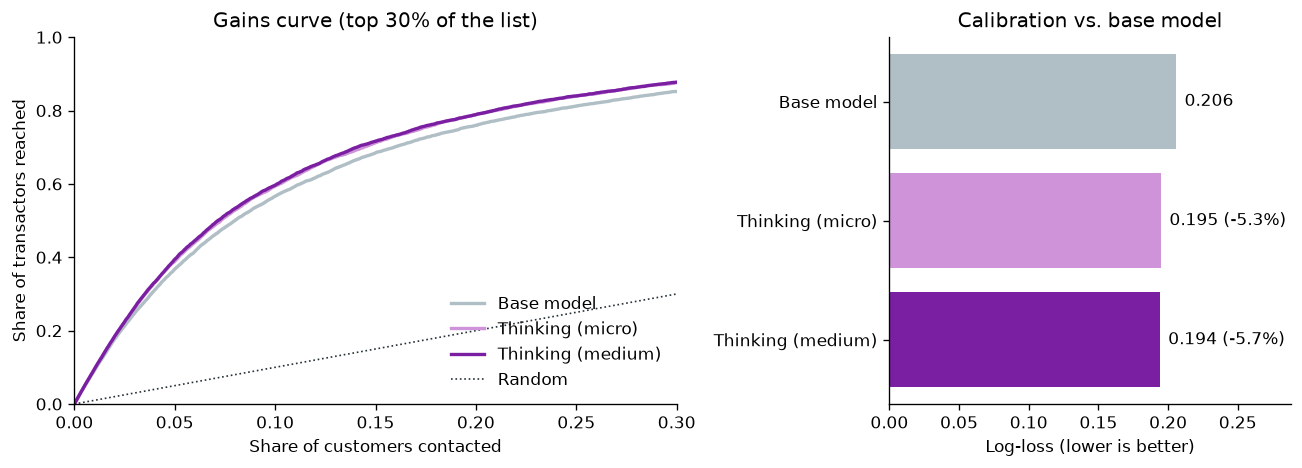

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [3, 2]})
colors = {"Base model": "#b0bec5", "Thinking (micro)": "#ce93d8", "Thinking (medium)": "#7B1FA2"}
for name, score in scores.items():
    order = np.argsort(-score)
    captured = np.cumsum(y_test[order]) / y_test.sum()
    contacted = np.arange(1, len(order) + 1) / len(order)
    left.plot(contacted, captured, color=colors[name], label=name, linewidth=2)
left.plot([0, 1], [0, 1], color="#263238", linestyle=":", linewidth=1, label="Random")
left.set_xlim(0, 0.3)
left.set_ylim(0, 1)
left.set(xlabel="Share of customers contacted", ylabel="Share of transactors reached",
         title="Gains curve (top 30% of the list)")
left.legend(frameon=False, loc="lower right")

ll = results["Log-loss"]
bars = right.barh(ll.index, ll, color=[colors[n] for n in ll.index])
labels = [f"{v:.3f}" if n == "Base model" else f"{v:.3f} ({(v / ll['Base model'] - 1) * 100:+.1f}%)"
          for n, v in ll.items()]
right.bar_label(bars, labels=labels, padding=5)
right.set_xlim(0, ll.max() * 1.4)
right.set(xlabel="Log-loss (lower is better)", title="Calibration vs. base model")
right.invert_yaxis()
fig.tight_layout()
plt.show()

![Customer targeting results](https://raw.githubusercontent.com/PriorLabs/tabpfn-cookbook/main/visuals/predict_customer_transactions_with_thinking_mode/targeting-results.png)

Thinking lifts the whole curve above the base model, and the two effort levels sit
almost on top of each other. Against the base model, ROC AUC moves from 0.895 to
0.907 with `"micro"` and 0.909 with `"medium"`; log-loss drops from 0.206 to 0.195
and 0.194, a 5 to 6% reduction; average precision rises from 0.603 to 0.648 and
0.653. The ranking gets better and the probabilities get better at the same time.

The gap is widest where campaigns operate. Contacting the top 10% of the base
model's list reaches 56.7% of all transactors; the same 10% of the Thinking list
reaches 59.4% with `"micro"` and 59.7% with `"medium"`. On this held-out set that is
roughly 200 more transactors for the same number of contacts, with no new data and
one extra argument in the constructor.

## What this means for targeting

Most of the value of a targeting model sits in a thin slice of the ranking, so a
modest headline gain turns into a larger practical one. An extra 0.012 of ROC AUC
sounds like noise. A 7% relative gain in average precision, and three more points
of recall in the top decile, is what a campaign budget notices.

The effort levels tell a second story. `"micro"` captures most of the improvement
in about six minutes. `"medium"` adds another 0.0016 of ROC AUC and three tenths of
a point of top-decile recall, for nine times the fit time. In an earlier run on the
same split, `"medium"` landed at 0.9075, level with `"micro"`, so that extra margin
is within run-to-run variation. Higher effort has more to work with on larger and
wider tables; at 133,000 rows and 600 columns, `"micro"` finds most of what there is
to find. Start there, compare on your own holdout, and pay for more effort only
when it moves the metric you care about.

Choose `thinking_metric` to match how the list will be used. We optimized ROC AUC
because it is the dataset's objective, and average precision and log-loss followed.
If only the top of the list will ever be acted on, passing
`thinking_metric="average_precision"` is the obvious next experiment.

## Takeaways

- Thinking mode improved every metric over the base model on a 133,000-row
  targeting problem: ROC AUC 0.895 to 0.909, log-loss 0.206 to 0.194, average
  precision 0.603 to 0.653, and 59.7% instead of 56.7% of transactors captured in
  the top 10% of the list.
- The improvement concentrates at the top of the ranking, where targeting happens,
  which is why average precision and the gains curve move more than ROC AUC.
- `"micro"` delivered most of it in about six minutes. `"medium"` took 51 minutes
  for a further small gain that an earlier run did not reproduce. Treat higher
  effort as something to test, not a default.
- Thinking is a fit-time cost paid once. Prediction speed and the rest of the
  pipeline do not change.